# Data Exploration & Preparation

**Project:** Time Series Forecaster — daily sales forecasting (Prophet + LSTM)

**Dataset:** `data/raw/sales_data.csv`

**Notebook goals:**
1. Load and understand the raw order-line data
2. Turn it into a daily sales time series
3. Investigate missing dates **before deciding how to handle them**
4. Establish a naive baseline with a proper time-based train/test split
5. Verify the Oct–Dec seasonality hypothesis


Load the raw data

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

project_root = Path("..").resolve()
csv_path = project_root / "data" / "raw" / "sales_data.csv"

print(f"Project root: {project_root}")
print(f"CSV path: {csv_path}")
df = pd.read_csv(csv_path, encoding="latin1")
df.head()

Project root: D:\projects\time-series-forecaster
CSV path: D:\projects\time-series-forecaster\data\raw\sales_data.csv


,ORDERNUMBER,QUANTITYORDERED,PRICEEACH,ORDERLINENUMBER,SALES,ORDERDATE,STATUS,QTR_ID,MONTH_ID,YEAR_ID,...,ADDRESSLINE1,ADDRESSLINE2,CITY,STATE,POSTALCODE,COUNTRY,TERRITORY,CONTACTLASTNAME,CONTACTFIRSTNAME,DEALSIZE
0,10107,30,95.70,2,2871.00,2/24/2003 0:00,Shipped,1,2,2003,...,897 Long Airport Avenue,NaN,NYC,NY,10022,USA,NaN,Yu,Kwai,Small
1,10121,34,81.35,5,2765.90,5/7/2003 0:00,Shipped,2,5,2003,...,59 rue de l'Abbaye,NaN,Reims,NaN,51100,France,EMEA,Henriot,Paul,Small
2,10134,41,94.74,2,3884.34,7/1/2003 0:00,Shipped,3,7,2003,...,27 rue du Colonel Pierre Avia,NaN,Paris,NaN,75508,France,EMEA,Da Cunha,Daniel,Medium
3,10145,45,83.26,6,3746.70,8/25/2003 0:00,Shipped,3,8,2003,...,78934 Hillside Dr.,NaN,Pasadena,CA,90003,USA,NaN,Young,Julie,Medium
4,10159,49,100.00,14,5205.27,10/10/2003 0:00,Shipped,4,10,2003,...,7734 Strong St.,NaN,San Francisco,CA,NaN,USA,NaN,Brown,Julie,Medium


In [3]:
df.info()
df.describe()
df.isnull().sum()

<class 'pandas.DataFrame'>
RangeIndex: 2823 entries, 0 to 2822
Data columns (total 25 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   ORDERNUMBER       2823 non-null   int64  
 1   QUANTITYORDERED   2823 non-null   int64  
 2   PRICEEACH         2823 non-null   float64
 3   ORDERLINENUMBER   2823 non-null   int64  
 4   SALES             2823 non-null   float64
 5   ORDERDATE         2823 non-null   str    
 6   STATUS            2823 non-null   str    
 7   QTR_ID            2823 non-null   int64  
 8   MONTH_ID          2823 non-null   int64  
 9   YEAR_ID           2823 non-null   int64  
 10  PRODUCTLINE       2823 non-null   str    
 11  MSRP              2823 non-null   int64  
 12  PRODUCTCODE       2823 non-null   str    
 13  CUSTOMERNAME      2823 non-null   str    
 14  PHONE             2823 non-null   str    
 15  ADDRESSLINE1      2823 non-null   str    
 16  ADDRESSLINE2      302 non-null    str    
 17  CITY  

ORDERNUMBER            0
QUANTITYORDERED        0
PRICEEACH              0
ORDERLINENUMBER        0
SALES                  0
ORDERDATE              0
STATUS                 0
QTR_ID                 0
MONTH_ID               0
YEAR_ID                0
PRODUCTLINE            0
MSRP                   0
PRODUCTCODE            0
CUSTOMERNAME           0
PHONE                  0
ADDRESSLINE1           0
ADDRESSLINE2        2521
CITY                   0
STATE               1486
POSTALCODE            76
COUNTRY                0
TERRITORY           1074
CONTACTLASTNAME        0
CONTACTFIRSTNAME       0
DEALSIZE               0
dtype: int64

In [4]:
df["STATUS"].value_counts()

STATUS
Shipped       2617
Cancelled       60
Resolved        47
On Hold         44
In Process      41
Disputed        14
Name: count, dtype: int64

I will keep only orders that actually produced revenue. `Cancelled` orders
(and optionally `Disputed`/`On Hold`) are removed; `Shipped` and `Resolved` count.
Adjust the filter below if you want a different rule — but document the choice
in the README either way.

In [5]:
# Keep only statuses that represent completed revenue
valid_statuses = ["Shipped", "Resolved"]
df = df[df["STATUS"].isin(valid_statuses)].copy()

print(f"Rows after status filter: {len(df)} (/2823)")

Rows after status filter: 2664 (/2823)


`ORDERDATE` is a string like `"2/24/2003 0:00"` (US format: month/day/year).
We parse it explicitly — relying on automatic inference is slower and can
silently mis-parse if the format ever changes.

In [6]:
df = df[["ORDERNUMBER", "QUANTITYORDERED", "PRICEEACH", "ORDERDATE", "SALES"]].copy()
df["ORDERDATE"] = pd.to_datetime(df["ORDERDATE"], format="%m/%d/%Y %H:%M")

df = df.rename(columns={
    "ORDERNUMBER": "order_number",
    "QUANTITYORDERED": "quantity_ordered",
    "PRICEEACH": "price_each",
    "ORDERDATE": "date",
    "SALES": "sales",
})

df = df.sort_values("date").reset_index(drop=True)
df.head()

,order_number,quantity_ordered,price_each,date,sales
0,10100,50,67.80,2003-01-06,3390.00
1,10100,30,100.00,2003-01-06,5151.00
2,10100,22,86.51,2003-01-06,1903.22
3,10100,49,34.47,2003-01-06,1689.03
4,10101,25,100.00,2003-01-09,3782.00


In [7]:
print(f"First date: {df['date'].min()}")
print(f"Last date:  {df['date'].max()}")
print(f"Unique dates with sales: {df['date'].nunique()} / {(df['date'].max() - df['date'].min()).days + 1}")

First date: 2003-01-06 00:00:00
Last date:  2005-05-17 00:00:00
Unique dates with sales: 240 / 863


Aggregation

In [8]:
    daily_sales = (
        df.groupby("date", as_index=False)["sales"]
          .sum()
          .rename(columns={"sales": "daily_sales"})
    )
    
    print(f"Rows: {len(daily_sales)}")
    print(f"First date: {daily_sales['date'].min()}")
    print(f"Last date:  {daily_sales['date'].max()}")
    daily_sales["daily_sales"].describe()

Rows: 240
First date: 2003-01-06 00:00:00
Last date:  2005-05-17 00:00:00


count       240.000000
mean      39342.580667
std       26175.933640
min         553.950000
25%       19915.017500
50%       37119.900000
75%       53722.127500
max      137644.720000
Name: daily_sales, dtype: float64

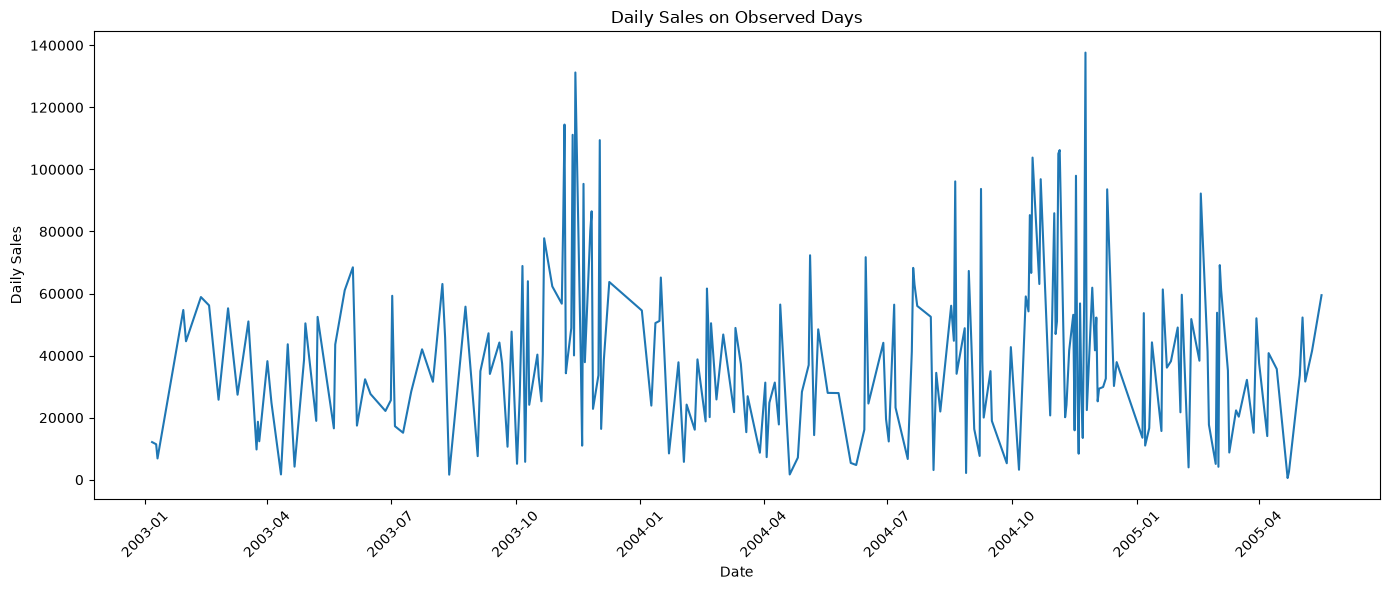

In [9]:
plt.figure(figsize=(14, 6))
plt.plot(daily_sales["date"], daily_sales["daily_sales"])
plt.xlabel("Date")
plt.ylabel("Daily Sales")
plt.title("Daily Sales on Observed Days")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Gap analysis — what do the missing dates mean?

252 observed days out of 877 calendar days. 
are missing dates "the store sold nothing", or "no record was collected"?

The weekday breakdown below answers this: if even *weekdays* are missing
60–70% of the time, the store clearly operates on days with no records —
so a missing date means **missing data, not zero sales**.

In [10]:
date_range = pd.date_range(
    start=daily_sales["date"].min(),
    end=daily_sales["date"].max(),
    freq="D"
)
missing_dates = date_range.difference(daily_sales["date"])

total_weekdays = pd.Series(date_range.day_name()).value_counts()
missing_weekdays = pd.Series(missing_dates.day_name()).value_counts()

print(f"All calendar days:       {len(date_range)}")
print(f"Missing calendar days:   {len(missing_dates)}")
print()
print("Missing % of each weekday:")
print((missing_weekdays / total_weekdays * 100).round(1))

All calendar days:       863
Missing calendar days:   623

Missing % of each weekday:
Friday       61.0
Monday       70.2
Saturday     88.6
Sunday       93.5
Thursday     65.0
Tuesday      66.9
Wednesday    60.2
Name: count, dtype: float64


In [11]:
# Gaps between consecutive observed sales days
daily_sales["date"].diff().value_counts()

date
1 days     87
2 days     35
3 days     22
6 days     21
4 days     20
5 days     16
7 days     15
8 days      9
11 days     4
9 days      4
19 days     2
12 days     2
24 days     1
10 days     1
Name: count, dtype: int64

Decision: **NOT zero-fill**

- ~65% of *weekdays* have no records → the business operates on days it
  doesn't record. Filling 625 dates with `0` would teach the model that
  sales collapse to zero most days.


Time-based train/test split + naive baseline

Train on the past, test on the most recent
observations. With 252 observed days we hold out the last ~50 (~20%).

In [12]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Chronological split on the observed series
test_size = 50
train = daily_sales.iloc[:-test_size].copy()
test  = daily_sales.iloc[-test_size:].copy()

print(f"Train: {len(train)} days | {train['date'].min().date()} -> {train['date'].max().date()}")
print(f"Test:  {len(test)} days | {test['date'].min().date()} -> {test['date'].max().date()}")

Train: 190 days | 2003-01-06 -> 2004-12-01
Test:  50 days | 2004-12-02 -> 2005-05-17


In [13]:
# Rolling naive forecast: prediction for each test day = previous observed day
naive_preds = np.concatenate([
    [train["daily_sales"].iloc[-1]],   # first test prediction = last train value
    test["daily_sales"].iloc[:-1].values  # after that, each prediction = previous actual
])

naive_mae  = mean_absolute_error(test["daily_sales"], naive_preds)
naive_rmse = np.sqrt(mean_squared_error(test["daily_sales"], naive_preds))

# MAPE only where actual sales > 0 (avoid division-by-near-zero distortion)
nonzero = test["daily_sales"] > 0
naive_mape = (
    np.abs((test.loc[nonzero, "daily_sales"] - naive_preds[nonzero.values])
           / test.loc[nonzero, "daily_sales"]).mean() * 100
)

print(f"Naive baseline -> MAE: ${naive_mae:,.0f} | RMSE: ${naive_rmse:,.0f} | MAPE: {naive_mape:.1f}%")

Naive baseline -> MAE: $25,262 | RMSE: $30,767 | MAPE: 257.2%


MAE (Mean Absolute Error) = average absolute difference between the prediction and the actual sales.
RMSE is similar to MAE, but it penalizes large errors more heavily. RMSE > MAE => $30,767 > $25,262.
MAPE measures the error relative to the actual value. 257% means that, on average, the absolute error is about 2.57 times the actual value.

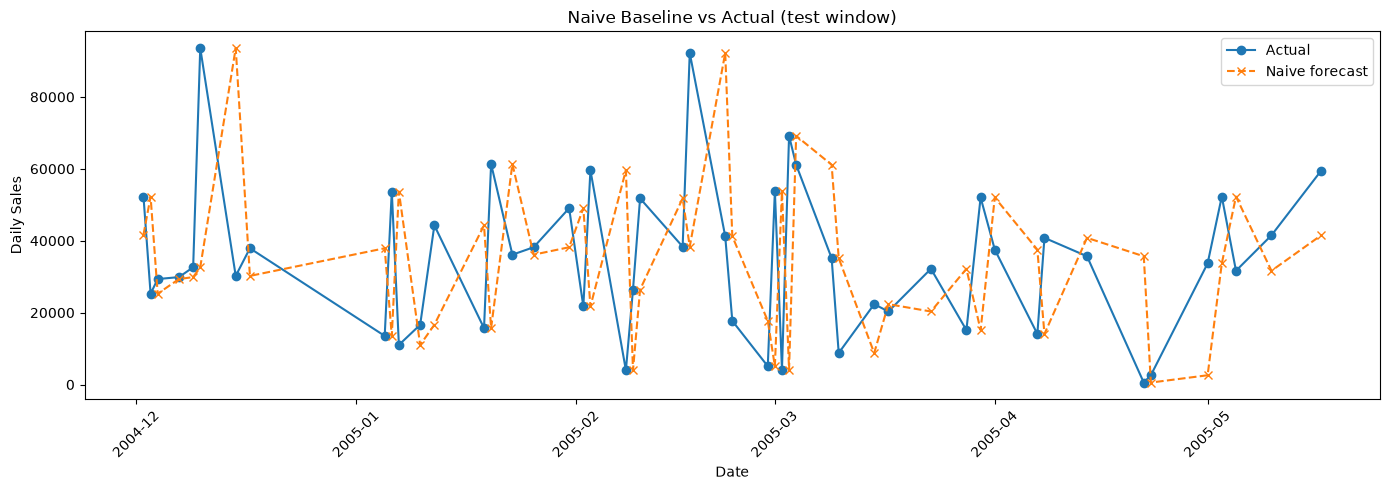

In [14]:
# Plot actual vs naive forecast on the test window
plt.figure(figsize=(14, 5))
plt.plot(test["date"], test["daily_sales"], marker="o", label="Actual")
plt.plot(test["date"], naive_preds, marker="x", linestyle="--", label="Naive forecast")
plt.xlabel("Date")
plt.ylabel("Daily Sales")
plt.title("Naive Baseline vs Actual (test window)")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Seasonality check — Oct–Dec peak

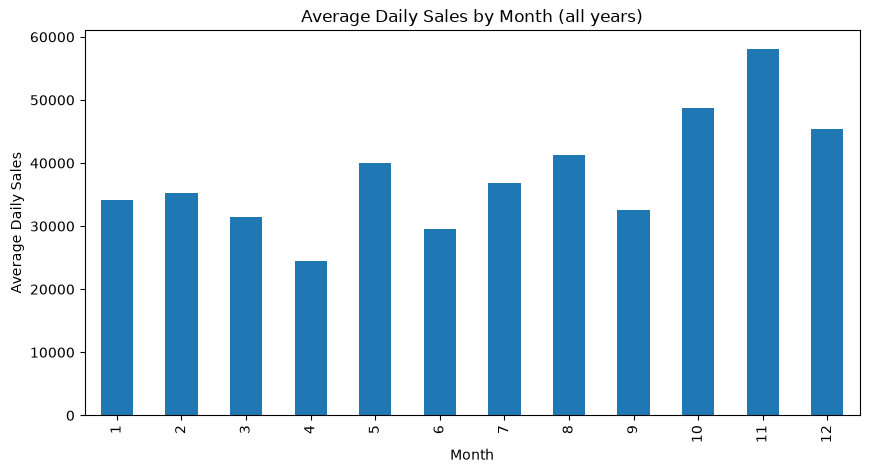

In [15]:
daily_sales["month"] = daily_sales["date"].dt.month
daily_sales["year"]  = daily_sales["date"].dt.year

monthly_pattern = daily_sales.groupby("month")["daily_sales"].mean()

monthly_pattern.plot(kind="bar", figsize=(10, 5),
                     title="Average Daily Sales by Month (all years)")
plt.xlabel("Month")
plt.ylabel("Average Daily Sales")
plt.show()

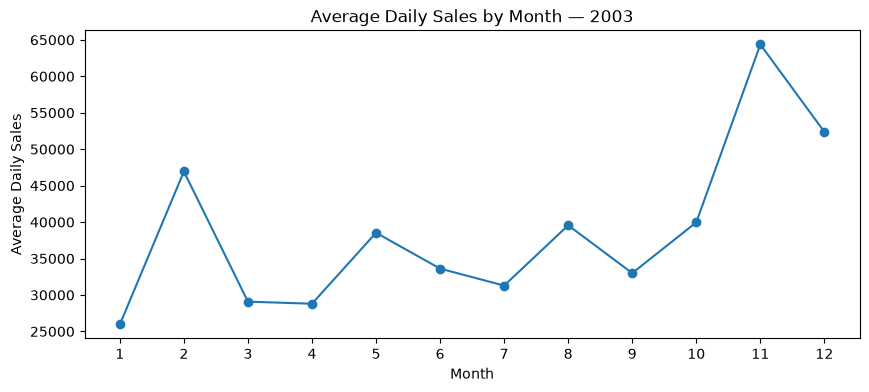

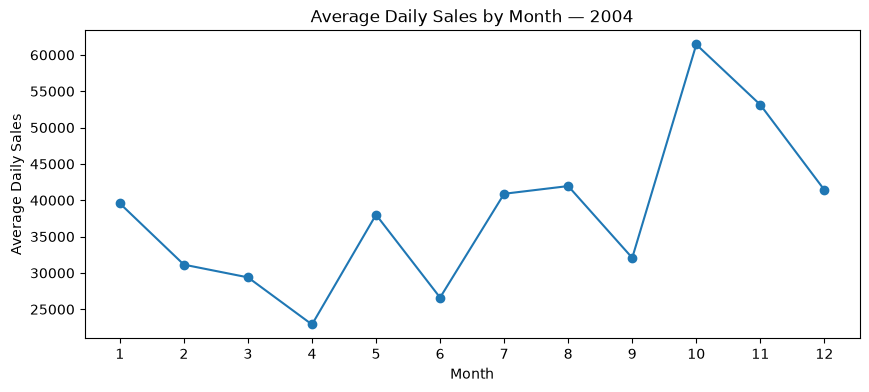

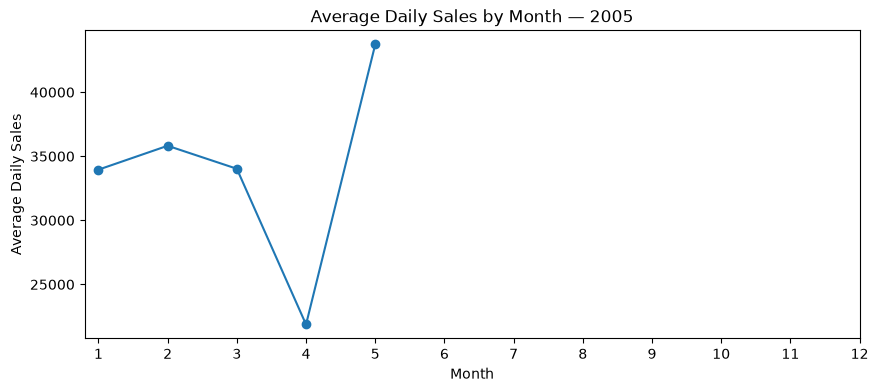

In [16]:
year_month = (
    daily_sales
    .groupby(["year", "month"])["daily_sales"]
    .mean()
    .reset_index()
)

for year in sorted(year_month["year"].unique()):
    data = year_month[year_month["year"] == year]
    plt.figure(figsize=(10, 4))
    plt.plot(data["month"], data["daily_sales"], marker="o")
    plt.title(f"Average Daily Sales by Month — {year}")
    plt.xlabel("Month")
    plt.ylabel("Average Daily Sales")
    plt.xticks(range(1, 13))
    plt.show()